# Assignment: ANN Salary Regression

Use the same `Churn_Modelling.csv` dataset, but change the target to `EstimatedSalary`. Your goal is to practice how an ANN changes when the task changes from classification to regression.

## Required Changes
- Target: `EstimatedSalary`
- Remove `EstimatedSalary` from input features
- Output layer: 1 neuron with **linear** activation
- Loss: choose `mse` or `mae` and explain your choice
- Evaluation: MAE, RMSE and R2
- Save the model in `.keras` format
- Build and deploy a Streamlit salary prediction app

## Step 1 - Imports

In [187]:
# Write your imports here

# Data handling and numerical calculations
import numpy as np
import pandas as pd

# charts for EDA (exploratory data analysis)
import matplotlib.pyplot as plt
import seaborn as sns

# splitting data, preparing features, and measuring regression performance
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# saving and reloading preprocessing objects
import joblib

# building and training the ANN (Artifical neural network)
import tensorflow as tf
from tensorflow import keras

# working with project files and folders
from pathlib import Path

## Step 2 - Load and inspect the dataset

In [188]:
data = pd.read_csv('Churn_Modelling.csv')
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## Step 3 - EDA and data quality checks

Rows: 10,000
Columns: 14

Column Names:


['RowNumber',
 'CustomerId',
 'Surname',
 'CreditScore',
 'Geography',
 'Gender',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited']

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
CustomerId,10000.0,NaN,NaN,NaN,15690940.5694,71936.186123,15565701.0,15628528.25,15690738.0,15753233.75,15815690.0
Surname,10000,2932,Smith,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CreditScore,10000.0,NaN,NaN,NaN,650.5288,96.653299,350.0,584.0,652.0,718.0,850.0
Geography,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,10000.0,NaN,NaN,NaN,38.9218,10.487806,18.0,32.0,37.0,44.0,92.0
Tenure,10000.0,NaN,NaN,NaN,5.0128,2.892174,0.0,3.0,5.0,7.0,10.0
Balance,10000.0,NaN,NaN,NaN,76485.889288,62397.405202,0.0,0.0,97198.54,127644.24,250898.09
NumOfProducts,10000.0,NaN,NaN,NaN,1.5302,0.581654,1.0,1.0,1.0,2.0,4.0


,Missing values,Missing values percent
RowNumber,0,0.0
CustomerId,0,0.0
Surname,0,0.0
CreditScore,0,0.0
Geography,0,0.0
Gender,0,0.0
Age,0,0.0
Tenure,0,0.0
Balance,0,0.0
NumOfProducts,0,0.0


Duplicated rows: 0


count     10000.000000
mean     100090.239881
std       57510.492818
min          11.580000
25%       51002.110000
50%      100193.915000
75%      149388.247500
max      199992.480000
Name: EstimatedSalary, dtype: float64

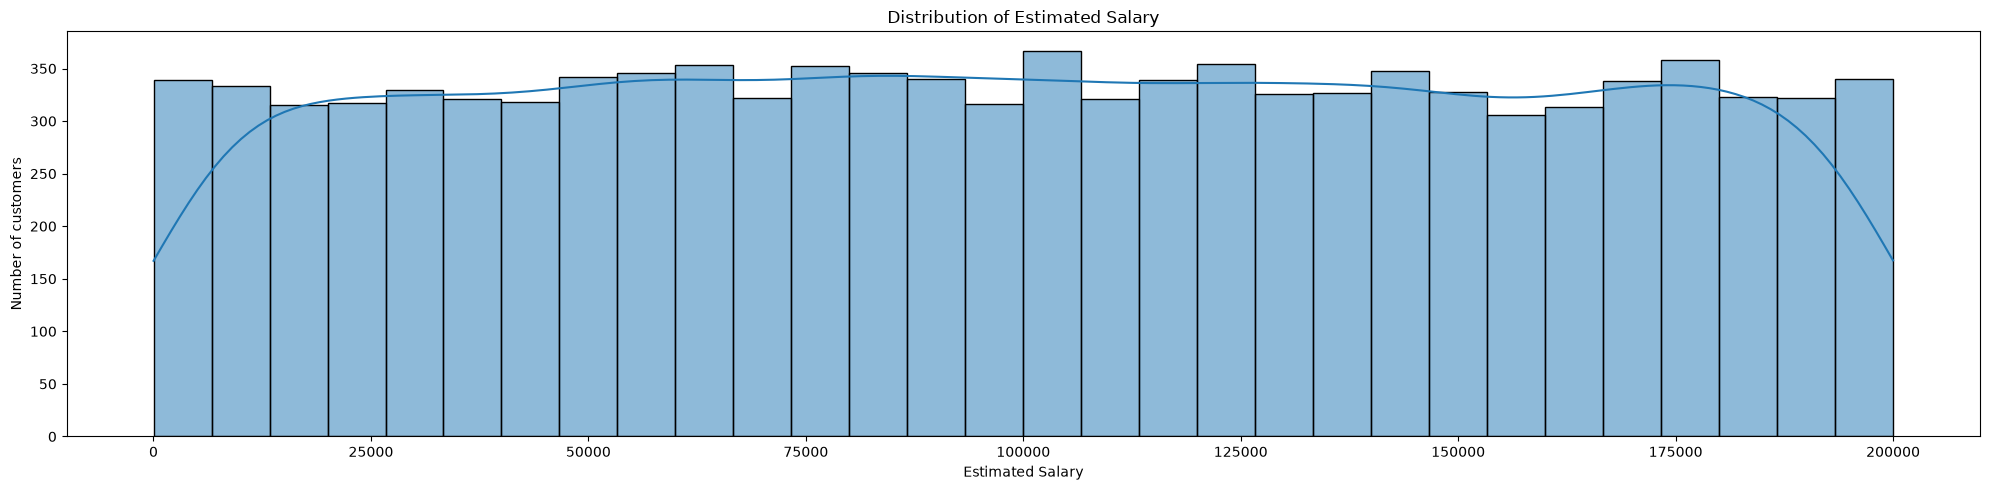

In [189]:
# shape, info, describe, missing values, duplicates, salary distribution

# Check the dataset size and column names
print(f"Rows: {data.shape[0]:,}")
print(f"Columns: {data.shape[1]}")
print("\nColumn Names:")
display(data.columns.to_list())

# check data type and non-missing values in each column
data.info()

# review summary statistics for numeric and categorical columns
display(data.describe(include="all").T)

# count missing values in each column
missing_report = pd.DataFrame({
    "Missing values": data.isna().sum(),
    "Missing values percent":(data.isna().mean() * 100).round(2)
})
display(missing_report)

# check for completely duplicated rows
print(f"Duplicated rows: {data.duplicated().sum():,}")

# review the salary target's summary statistics
display(data["EstimatedSalary"].describe())

# Visualize the salary distribution
plt.figure(figsize=(20,5))
sns.histplot(data=data, x="EstimatedSalary", bins=30, kde=True)
plt.title("Distribution of Estimated Salary")
plt.xlabel("Estimated Salary")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

# Step 4 — Define the input features and target

In [190]:
# y = EstimatedSalary
# X = remaining useful features

# Customer identifiers do not help the model predict salary
identifier_columns = ['RowNumber','CustomerId','Surname']

# This is the value or model will predict
target_column = "EstimatedSalary"

# X contains the input features; remove identifiers and the target
X = data.drop(columns=identifier_columns + [target_column])

# y contains the target values
y = data[target_column]

#check the results
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"\nInput features: {X.columns.to_list()}")

display(X.head())
display(y.head())

X shape: (10000, 10)
y shape: (10000,)

Input features: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'Exited']


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,Exited
0,619,France,Female,42,2,0.00,1,1,1,1
1,608,Spain,Female,41,1,83807.86,1,0,1,0
2,502,France,Female,42,8,159660.80,3,1,0,1
3,699,France,Female,39,1,0.00,2,0,0,0
4,850,Spain,Female,43,2,125510.82,1,1,1,0


0    101348.88
1    112542.58
2    113931.57
3     93826.63
4     79084.10
Name: EstimatedSalary, dtype: float64

## Step 5 - Train-test split and preprocessing

In [191]:
# Fit encoders and scaler on training data only

# split the data: 80% for training and 20% for final testing

X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)

# find which input columns contain numbers and which contain categories
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=['object','category']
).columns.tolist()

# scale numeric inputs and turn text categories into numeric columns
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), numeric_features),
        (
            'catgorical',
            OneHotEncoder(handle_unknown='ignore', sparse_output=False),categorical_features
        )
    ]
)

# learn preprocessing rules from training data only
X_train_processed = preprocessor.fit_transform(X_train).astype(np.float32)

# apply those same rules to the test data
X_test_processed = preprocessor.transform(X_test).astype(np.float32)

# scale salaries using training salaries only, keep y_test in salary units
target_scaler = StandardScaler()
y_train_scaled = target_scaler.fit_transform(
    y_train.to_numpy().reshape(-1,1)
).astype(np.float32)

# check the results
print(f"Training input shape: {X_train_processed.shape}")
print(f"Testing input shape: {X_test_processed.shape}")
print(f"Training salary shape: {y_train_scaled.shape}")
print(f"Testing salary shape: {y_test.shape}")

Training input shape: (8000, 13)
Testing input shape: (2000, 13)
Training salary shape: (8000, 1)
Testing salary shape: (2000,)


C:\Users\syedv\AppData\Local\Temp\ipykernel_67396\2838779279.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


## Step 6 - Build a regression ANN

In [192]:
# Example structure only
# model = keras.Sequential([
#     keras.Input(shape=(X_train.shape[1],)),
#     keras.layers.Dense(64, activation='relu'),
#     keras.layers.Dense(32, activation='relu'),
#     keras.layers.Dense(1, activation='linear')
# ])

# create a sequential ANN: each layer passes its output to the next layer
model = keras.Sequential(
    [
        # the number of inputs matches the processed feature count from step 5
        keras.Input(shape=(X_train_processed.shape[1],), name ='input_features'),

        # hidden layers learn patterns in the input features
        keras.layers.Dense(64, activation="relu", name="hidden_layer_1"),
        keras.layers.Dense(32, activation="relu", name="hidden_layer_2"),

        # one linear output produces a continous regression value
        keras.layers.Dense(1, activation="linear", name="salar_output"),
    ],
    name = "salary_regression_ann"
)

# review the model's layers and parameter counts
model.summary()

Model: "salary_regression_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salar_output (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,009 (11.75 KB)

 Trainable params: 3,009 (11.75 KB)

 Non-trainable params: 0 (0.00 B)

## Step 7 - Compile and train

In [193]:
# optimizer=Adam, loss='mse' or 'mae', include a suitable regression metric

# configure how the model learns
model.compile(
    optimizer = keras.optimizers.Adam(learning_rate=0.001),
    loss = "mse",
    metrics=["mae"]
)

# stop if validation loss does not improve for 10 consecutive epochs.
# restore the weights from the best epoch
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

# train on the training data and use 20% of it for validation
history = model.fit(
    X_train_processed,
    y_train_scaled,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

print(f"Training completed after {len(history.history['loss'])} epochs.")

Epoch 1/100


200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.0274 - mae: 0.8727 - val_loss: 1.0088 - val_mae: 0.8656
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0013 - mae: 0.8623 - val_loss: 1.0049 - val_mae: 0.8634
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9947 - mae: 0.8593 - val_loss: 1.0108 - val_mae: 0.8650
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9892 - mae: 0.8562 - val_loss: 1.0081 - val_mae: 0.8654
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9856 - mae: 0.8546 - val_loss: 1.0051 - val_mae: 0.8626
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9807 - mae: 0.8532 - val_loss: 1.0099 - val_mae: 0.8665
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9782 - mae: 0.8517 - val_loss: 1.0123 - val_mae: 0.8664
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9752 - mae: 0.8503 - val_loss: 1.0147 - val_mae: 0.8674
Epoch 9/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss:

## Step 8 - Evaluate

In [194]:
# Calculate MAE, RMSE and R2 on the untouched test set

# predict scaled salaries fromt the test inputs
y_pred_scaled = model.predict(X_test_processed, verbose=0)

# convert model predictions back to the original salary scale
y_pred = target_scaler.inverse_transform(y_pred_scaled).ravel()

# convert actual test salaries to a one-dimensional Numpy array
y_test_actual = y_test.to_numpy().ravel()

# calculate evaluation metrics in the dataset's salary units
mae = mean_absolute_error(y_test_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred))
r2 = r2_score(y_test_actual, y_pred)

print(f"MAE: {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²: {r2:,.4f}")

MAE: 50,176.64
RMSE: 58,003.45
R²: -0.0191


## Step 9 - Save and reload model

In [195]:
# model.save('salary_model.keras')

# create an artifacts folder inside the project folder
ARTIFACTS_DIR = Path.cwd() / "artifacts"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# set paths for the saved files
MODEL_PATH = ARTIFACTS_DIR / "salary_model.keras"
PREPROCESSING_PATH = ARTIFACTS_DIR / "preprocessing.joblib"

# save the trained ANN in Keras format
model.save(MODEL_PATH)

# save the fitted preprocessing objects and input column order
joblib.dump(
    {
        "preprocessor": preprocessor,
        "target_scaler": target_scaler,
        "feature_columns": X.columns.to_list()
    },
    PREPROCESSING_PATH
)

# reload both files, as the Streamlit app will do
loaded_model = keras.models.load_model(MODEL_PATH)
loaded_artifacts = joblib.load(PREPROCESSING_PATH)

# make predictions for five test customers using the reloaded files
sample_inputs = X_test.iloc[:5]
sample_inputs_processed = loaded_artifacts["preprocessor"].transform(
    sample_inputs
).astype(np.float32)

sample_predictions_scaled = loaded_model.predict(
    sample_inputs_processed,
    verbose=0
)

sample_predictions = loaded_artifacts["target_scaler"].inverse_transform(
    sample_predictions_scaled
).ravel()

# compare actual and predicted salaries
display(pd.DataFrame({
    "Actual Salary": y_test.iloc[:5].to_numpy(),
    "Predicted salary": sample_predictions
}))

print(f"Model saved to: {MODEL_PATH}")
print(f"Preprocssing saved to: {PREPROCESSING_PATH}")

,Actual Salary,Predicted salary
0,41788.37,98252.164062
1,146379.30,98000.875000
2,58561.31,99740.812500
3,170679.74,101084.601562
4,114669.79,100309.226562


Model saved to: d:\Working\Learning\DS and AI Cohort-03\Data science Batch 06-20261111T053219Z-1-001\Data science Batch 06\Class13_14_15\Assignment\Churn_modelling_regression\artifacts\salary_model.keras
Preprocssing saved to: d:\Working\Learning\DS and AI Cohort-03\Data science Batch 06-20261111T053219Z-1-001\Data science Batch 06\Class13_14_15\Assignment\Churn_modelling_regression\artifacts\preprocessing.joblib


## Step 10 - Streamlit deployment

In [196]:
# Build app.py, requirements.txt, README.md and deploy on Streamlit Community Cloud



## Reflection Questions
1. Why did we remove sigmoid from the output layer?
2. Why is Binary Cross-Entropy not suitable here?
3. What does MAE mean in salary units?
4. If RMSE is much larger than MAE, what might that suggest?
5. What are the limitations of predicting salary from this classroom dataset?